# Practical 3: Regression Modelling
**Project:** Groundwater Level Prediction & Risk Classification

**Input file:** `02_clean_wells.csv` (saved by Practical 2)
**Output files:** `03_wells_with_risk.csv` (risk classes + train/test split, used by Practicals 4 to 6) and `04_regression_results.csv`

**Aim:** predict the 2022 water depth of each well using Simple, Multiple and Polynomial regression, study OLS and correlations, evaluate with MAE, MSE, RMSE and R-squared, and apply Logistic Regression to a yes/no risk question.

## Step 1: Load the clean data
**What to say:** *One row per well. The features come from 2015-2021 and the value to predict is the 2022 depth.*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("02_clean_wells.csv")
print(df.shape)
df.head()

(1848, 29)


,Well_ID,State,District,TYPE,Latitude,Longitude,Well_Depth (meters),Pre_2015,Pre_2016,Pre_2017,...,Post_2019,Post_2020,Post_2021,Post_2022,pre_mean,post_mean,recharge,change,target_2022,dry_2022
0,G_1_BK_021,Gujarat,Banaskantha,Piezometer,24.44250,72.42000,60.00,16.3,9.4,15.4,...,11.2,3.1,16.90,12.30,15.392857,8.907143,6.485714,4.50,20.2,False
1,G_1_BK_018,Gujarat,Banaskantha,Piezometer,24.49694,72.38389,60.00,15.4,24.7,31.2,...,49.4,34.1,49.45,46.40,36.857143,29.035714,7.821429,42.80,51.4,False
2,G_1_BK_019,Gujarat,Banaskantha,Piezometer,24.36361,72.28944,60.00,22.1,21.1,21.3,...,21.2,19.1,18.15,60.00,22.735714,16.507143,6.228571,-2.65,60.0,True
3,G_1_BK_020,Gujarat,Banaskantha,Piezometer,24.35583,72.36389,60.00,12.9,13.0,15.8,...,10.2,2.7,6.80,6.45,11.571429,8.107143,3.464286,-2.10,12.4,False
4,BK-105,Gujarat,Banaskantha,Dug Well,24.55611,72.35083,28.35,16.7,16.8,23.4,...,13.9,10.0,19.80,20.30,18.228571,13.600000,4.628571,5.50,21.6,False


## Step 2: Create the risk classes
**What to say:** *Besides predicting the exact depth, I group each well into a risk level using its 2022 pre-monsoon depth, with bands similar to those used in CGWB water-level reports. A well that went dry is automatically Severe. These classes are used for logistic regression now, and for classification in Practicals 4 and 5.*

| Class | Depth to water |
|---|---|
| Safe | up to 10 m |
| Watch | 10 to 20 m |
| Critical | 20 to 40 m |
| Severe | over 40 m, or went dry |

In [2]:
def risk_class(depth, went_dry):
    if went_dry or depth > 40:
        return "Severe"
    elif depth > 20:
        return "Critical"
    elif depth > 10:
        return "Watch"
    else:
        return "Safe"

df["risk"] = df.apply(lambda row: risk_class(row["target_2022"], row["dry_2022"]), axis=1)
df["risk_code"] = df["risk"].map({"Safe": 0, "Watch": 1, "Critical": 2, "Severe": 3})

order = ["Safe", "Watch", "Critical", "Severe"]
print(df["risk"].value_counts()[order])

risk
Safe        730
Watch       412
Critical    302
Severe      404
Name: count, dtype: int64


risk         Safe  Watch  Critical  Severe
State                                     
Gujarat        71    100        88     238
Haryana        90    168       192     164
Maharashtra   569    144        22       2


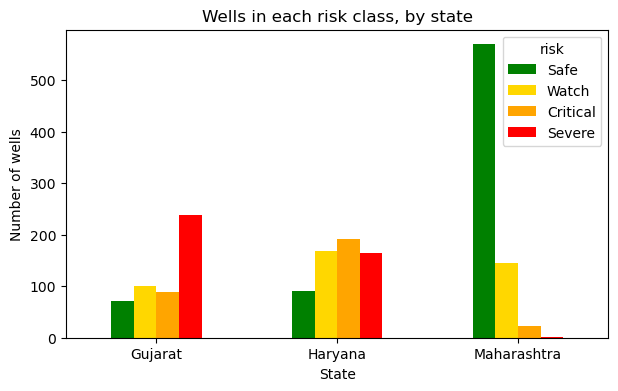

In [3]:
table = pd.crosstab(df["State"], df["risk"])[order]
print(table)

table.plot(kind="bar", figsize=(7, 4), color=["green", "gold", "orange", "red"])
plt.title("Wells in each risk class, by state")
plt.ylabel("Number of wells")
plt.xticks(rotation=0)
plt.show()

**What to say:** *Risk is very uneven: Maharashtra is mostly Safe, while Gujarat and Haryana have many Critical and Severe wells. So location matters a lot.*

## Step 3: Split into training and test sets, then save
**What to say:** *I train the models on 80% of the wells and test them on the hidden 20%. The split is saved in the file (column 'set'), so every later practical uses exactly the same wells and the comparison between models is fair.*

In [4]:
from sklearn.model_selection import train_test_split

train_part, test_part = train_test_split(df, test_size=0.2, random_state=42, stratify=df["risk"])
df["set"] = "train"
df.loc[test_part.index, "set"] = "test"

df.to_csv("03_wells_with_risk.csv", index=False)
print(df["set"].value_counts())
print("Saved 03_wells_with_risk.csv")

set
train    1478
test      370
Name: count, dtype: int64
Saved 03_wells_with_risk.csv


## Step 4: Correlations
**What to say:** *Correlation shows how strongly two numbers move together: +1 means perfectly together, 0 means unrelated, -1 means opposite. Past average depth and last known depth are almost the same as the answer. This is expected because groundwater changes slowly.*

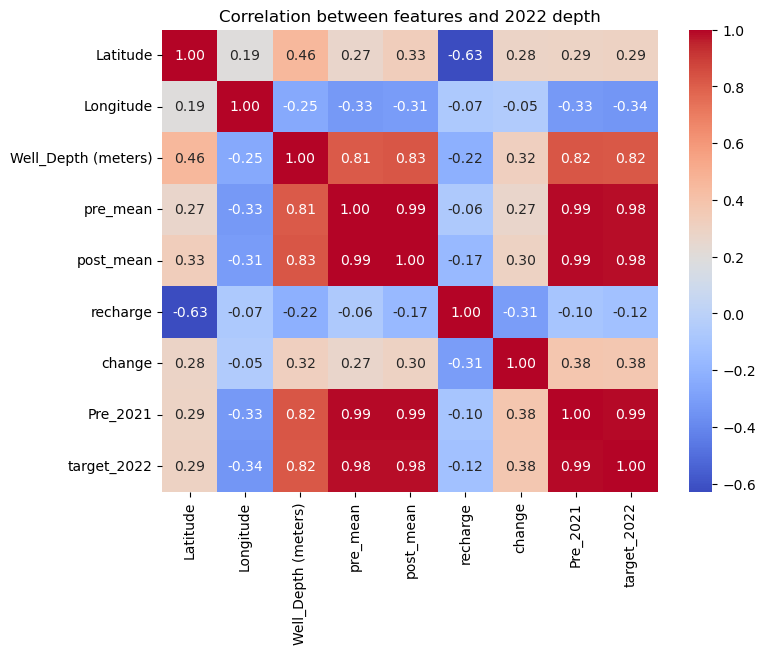

Pre_2021               0.99
pre_mean               0.98
post_mean              0.98
Well_Depth (meters)    0.82
change                 0.38
Latitude               0.29
recharge              -0.12
Longitude             -0.34
dtype: float64


In [5]:
features = ["Latitude", "Longitude", "Well_Depth (meters)", "pre_mean", "post_mean", "recharge", "change", "Pre_2021"]

plt.figure(figsize=(8, 6))
sns.heatmap(df[features + ["target_2022"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between features and 2022 depth")
plt.show()

print(df[features].corrwith(df["target_2022"]).round(2).sort_values(ascending=False))

## Step 5: Prepare the data and set a baseline
**What to say:** *Before building models I need a simple guess to beat. My baseline says: next year's depth will be the same as the last known depth (2021). If a model cannot beat this, it is not adding value. Models are judged with four measures: MAE (average error in metres), MSE (average squared error), RMSE (square root of MSE, in metres, punishes big errors) and R-squared (share of the variation explained, 1 is perfect).*

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

train = df[df["set"] == "train"]
test = df[df["set"] == "test"]
y_train = train["target_2022"]
y_test = test["target_2022"]

def scores(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"Model": name,
            "MAE": mean_absolute_error(y_true, y_pred),
            "MSE": mse,
            "RMSE": mse ** 0.5,
            "R2": r2_score(y_true, y_pred)}

results = []
results.append(scores("Baseline (same as 2021)", y_test, test["Pre_2021"]))
pd.DataFrame(results).round(2)

,Model,MAE,MSE,RMSE,R2
0,Baseline (same as 2021),1.94,31.0,5.57,0.97


## Step 6: Simple Linear Regression
**What to say:** *One input (average past depth) is used to predict the 2022 depth: depth = intercept + slope x pre_mean.*

In [7]:
from sklearn.linear_model import LinearRegression

simple = LinearRegression()
simple.fit(train[["pre_mean"]], y_train)
pred_simple = simple.predict(test[["pre_mean"]])

print("Slope:", round(simple.coef_[0], 3), "| Intercept:", round(simple.intercept_, 3))
results.append(scores("Simple Linear", y_test, pred_simple))

Slope: 1.053 | Intercept: -0.682


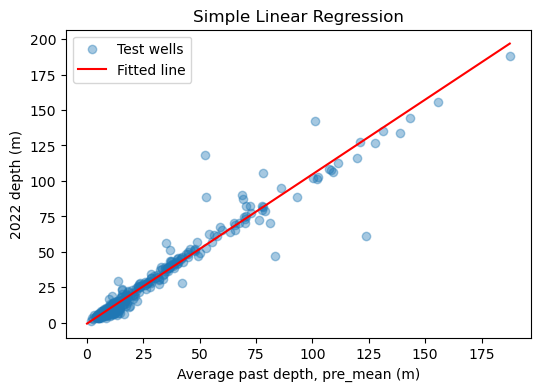

In [8]:
plt.figure(figsize=(6, 4))
plt.scatter(test["pre_mean"], y_test, alpha=0.4, label="Test wells")
line_x = np.linspace(0, test["pre_mean"].max(), 100)
plt.plot(line_x, simple.intercept_ + simple.coef_[0] * line_x, color="red", label="Fitted line")
plt.xlabel("Average past depth, pre_mean (m)")
plt.ylabel("2022 depth (m)")
plt.legend()
plt.title("Simple Linear Regression")
plt.show()

## Step 7: Multiple Linear Regression
**What to say:** *Now I use all 8 features together instead of one. Each coefficient shows how much the predicted depth changes when that feature rises by one unit, keeping the others the same.*

In [9]:
multiple = LinearRegression()
multiple.fit(train[features], y_train)
pred_multiple = multiple.predict(test[features])

print(pd.Series(multiple.coef_, index=features).round(3))
results.append(scores("Multiple Linear", y_test, pred_multiple))

Latitude               0.022
Longitude             -0.391
Well_Depth (meters)    0.002
pre_mean               0.129
post_mean              0.166
recharge              -0.037
change                 0.102
Pre_2021               0.711
dtype: float64


## Step 8: Polynomial Regression
**What to say:** *This allows a curved relationship (depth squared), in case very deep wells change differently from shallow ones.*

In [10]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(train[["pre_mean"]])
X_test_poly = poly.transform(test[["pre_mean"]])

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)
pred_poly = poly_model.predict(X_test_poly)

results.append(scores("Polynomial (degree 2)", y_test, pred_poly))

## Step 9: OLS (Ordinary Least Squares) with statsmodels
**What to say:** *OLS is the method that linear regression uses: it chooses the line that makes the sum of squared errors as small as possible. The statsmodels version also gives p-values. A p-value below 0.05 means the feature has a statistically significant effect.*

In [11]:
import statsmodels.api as sm

X_ols = sm.add_constant(train[features])       # adds the intercept term
ols = sm.OLS(y_train, X_ols).fit()

summary = pd.DataFrame({"coefficient": ols.params, "p_value": ols.pvalues}).round(4)
summary["significant (p < 0.05)"] = summary["p_value"] < 0.05
print(summary)
print("R-squared on training data:", round(ols.rsquared, 3))

                     coefficient  p_value  significant (p < 0.05)
const                    29.3482   0.0000                    True
Latitude                  0.0216   0.5984                   False
Longitude                -0.3913   0.0000                    True
Well_Depth (meters)       0.0025   0.5444                   False
pre_mean                  0.1293   0.0061                    True
post_mean                 0.1665   0.0000                    True
recharge                 -0.0372   0.3537                   False
change                    0.1015   0.0167                    True
Pre_2021                  0.7113   0.0000                    True
R-squared on training data: 0.981


## Step 10: Compare all regression models
**What to say:** *Lower MAE, MSE and RMSE are better; R-squared closer to 1 is better. All numbers are on the 20% test wells the models never saw. MAE is the average error in metres.*

                  Model  MAE   MSE  RMSE   R2
Baseline (same as 2021) 1.94 31.00  5.57 0.97
          Simple Linear 3.18 50.07  7.08 0.95
        Multiple Linear 2.02 28.38  5.33 0.97
  Polynomial (degree 2) 3.02 47.80  6.91 0.95


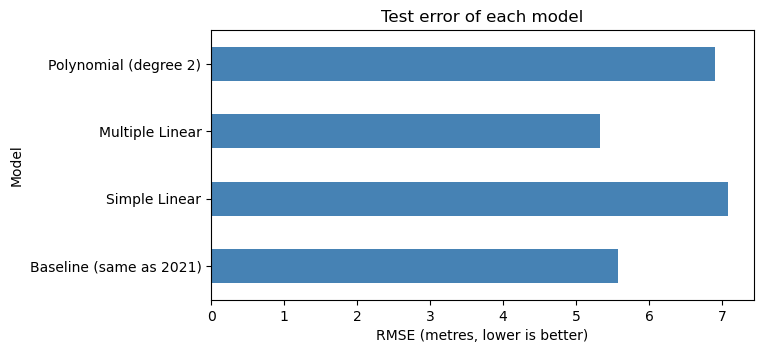

Saved 04_regression_results.csv


In [12]:
results_table = pd.DataFrame(results).round(2)
print(results_table.to_string(index=False))

results_table.plot(x="Model", y="RMSE", kind="barh", legend=False, figsize=(7, 3.5), color="steelblue")
plt.xlabel("RMSE (metres, lower is better)")
plt.title("Test error of each model")
plt.show()

results_table.to_csv("04_regression_results.csv", index=False)
print("Saved 04_regression_results.csv")

## Step 11: Actual vs predicted, and where the model is wrong
**What to say:** *Points on the red line are perfect predictions. I also checked the average error in each state.*

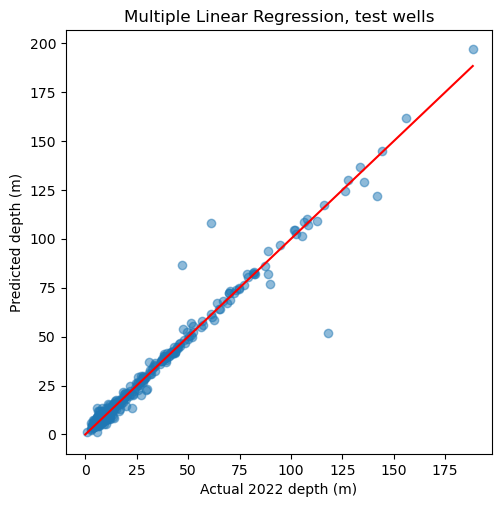

Average error (m) by state:
State
Gujarat        3.47
Haryana        1.43
Maharashtra    1.51
Name: target_2022, dtype: float64


In [13]:
plt.figure(figsize=(5.5, 5.5))
plt.scatter(y_test, pred_multiple, alpha=0.5)
limit = [0, y_test.max()]
plt.plot(limit, limit, color="red")
plt.xlabel("Actual 2022 depth (m)")
plt.ylabel("Predicted depth (m)")
plt.title("Multiple Linear Regression, test wells")
plt.show()

error = (y_test - pred_multiple).abs()
print("Average error (m) by state:")
print(error.groupby(test["State"]).mean().round(2))

## Step 12: Logistic Regression
**What to say:** *Logistic regression predicts a yes/no answer. The question here is: will a well be At Risk (Critical or Severe) in 2022? I scale the features first, fitting the scaler on training wells only so no test information leaks in.*

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix

df["at_risk"] = df["risk"].isin(["Critical", "Severe"]).astype(int)      # 1 = Critical or Severe
train = df[df["set"] == "train"]
test = df[df["set"] == "test"]

scaler = StandardScaler()
X_train = scaler.fit_transform(train[features])
X_test = scaler.transform(test[features])

logit = LogisticRegression(max_iter=1000)
logit.fit(X_train, train["at_risk"])
pred_risk = logit.predict(X_test)

print("Accuracy:", round(accuracy_score(test["at_risk"], pred_risk), 3))
print("At-risk wells found (recall):", round(recall_score(test["at_risk"], pred_risk), 3))
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(test["at_risk"], pred_risk))

Accuracy: 0.976
At-risk wells found (recall): 0.95
Confusion matrix (rows = actual, columns = predicted):
[[227   2]
 [  7 134]]


## Conclusion
**What to say:** *Groundwater depth changes slowly from year to year, so even the simple baseline predicts 2022 very well. This is why I compared every model with the baseline instead of only reporting R-squared. Logistic regression can separate at-risk wells from safe ones with high accuracy. In the next practicals I classify the four risk levels with more advanced models.*

---
**Next: Practical 4 (KNN and Naive Bayes)**, starting from `03_wells_with_risk.csv`.